In [161]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_excel("../data/CCPP/Folds5x2_pp.xlsx", sheet_name="Sheet1")
df.head()

,AT,V,AP,RH,PE
0,14.96,41.76,1024.07,73.17,463.26
1,25.18,62.96,1020.04,59.08,444.37
2,5.11,39.40,1012.16,92.14,488.56
3,20.86,57.32,1010.24,76.64,446.48
4,10.82,37.50,1009.23,96.62,473.90


(b)i. Rows and columns

In [162]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 9568
Number of columns: 5


Each row represents one hourly observation of the power plant operating at full load. Each column represents four independent variables and one dependent variable.

(b)ii. Pairwise Scatterplots

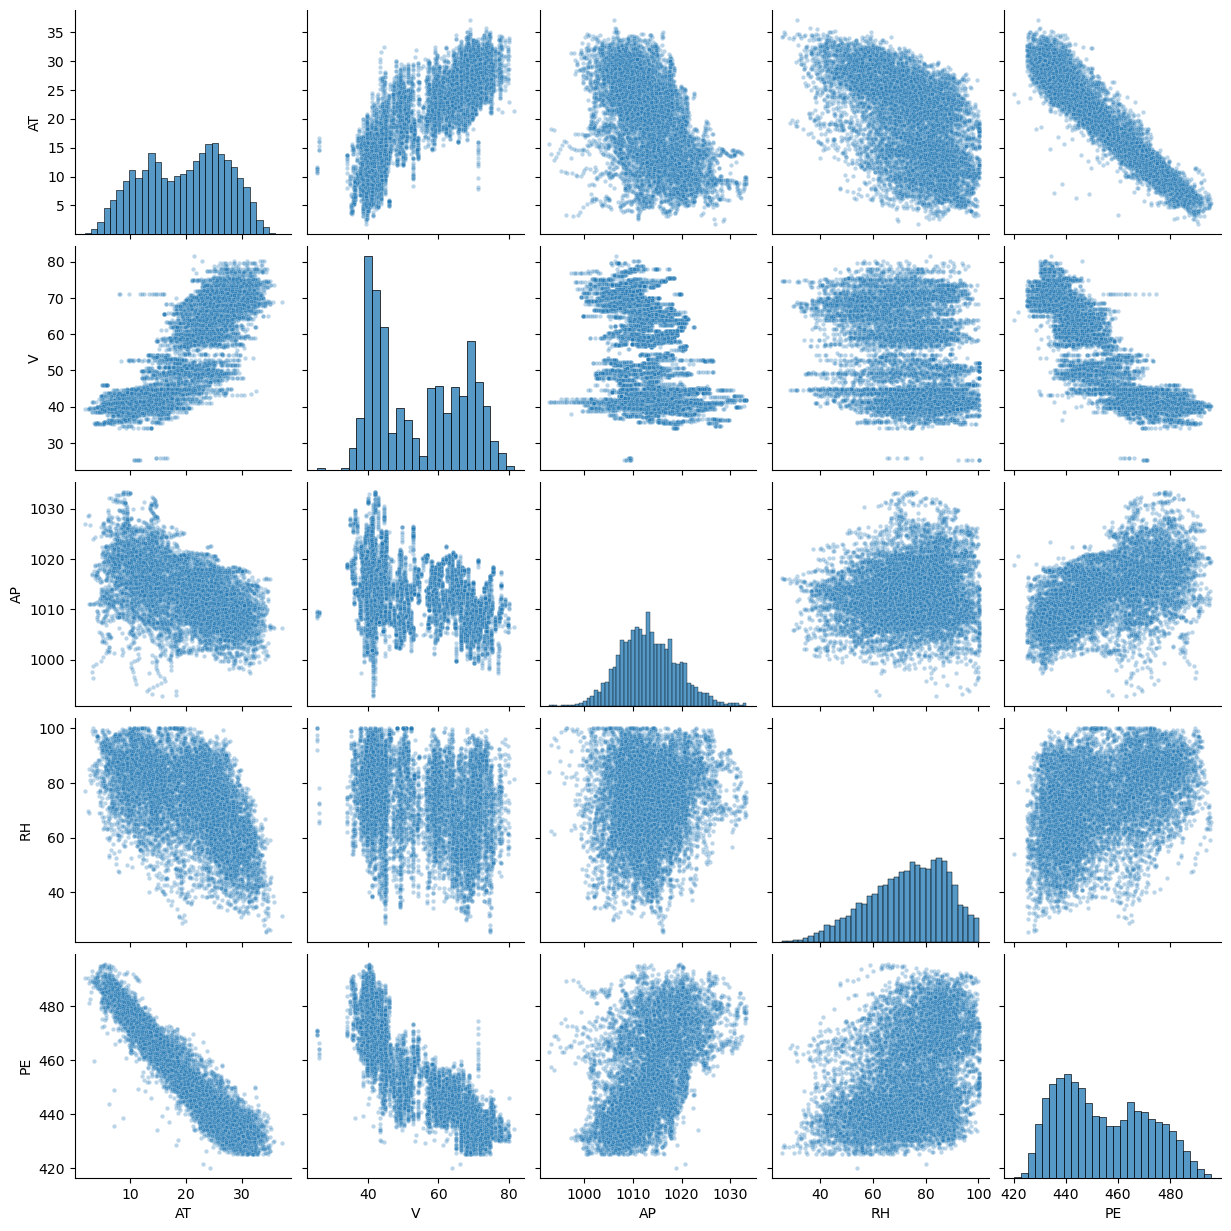

,AT,V,AP,RH,PE
AT,1.000,0.844,-0.508,-0.543,-0.948
V,0.844,1.000,-0.414,-0.312,-0.870
AP,-0.508,-0.414,1.000,0.100,0.518
RH,-0.543,-0.312,0.100,1.000,0.390
PE,-0.948,-0.870,0.518,0.390,1.000


In [163]:
sns.pairplot(
    df,
    diag_kind="hist",
    plot_kws={"alpha": 0.3, "s": 10}
)

plt.show()
df.corr().round(3)

AT and V have strong negative relationships with PE. As temperature or exhaust vacuum increases, electrical energy output generally decreases. AP has a moderate positive relationship with PE, while RH has a weaker positive relationship with PE. Among the predictors, AT and V have a strong positive relationship. AT also has negative relationships with AP and RH. Overall, AT has the strongest linear relationship with PE.

(b)iii.

In [164]:
summary = pd.DataFrame({
    "Mean": df.mean(),
    "Median": df.median(),
    "Range": df.max() - df.min(),
    "Q1": df.quantile(0.25),
    "Q3": df.quantile(0.75),
    "IQR": df.quantile(0.75) - df.quantile(0.25)
})

summary.round(3)

,Mean,Median,Range,Q1,Q3,IQR
AT,19.651,20.345,35.30,13.510,25.72,12.210
V,54.306,52.080,56.20,41.740,66.54,24.800
AP,1013.259,1012.940,40.41,1009.100,1017.26,8.160
RH,73.309,74.975,74.60,63.328,84.83,21.502
PE,454.365,451.550,75.50,439.750,468.43,28.680


(c) simple linear regression

In [165]:
import statsmodels.api as sm

predictors = ["AT", "V", "AP", "RH"]
simple_models = {}
results = []

for predictor in predictors:
    X = sm.add_constant(df[[predictor]])
    model = sm.OLS(df["PE"], X).fit()

    simple_models[predictor] = model

    results.append({
        "Predictor": predictor,
        "Intercept": model.params["const"],
        "Coefficient": model.params[predictor],
        "P-value": model.pvalues[predictor],
        "R-squared": model.rsquared
    })

results_df = pd.DataFrame(results).set_index("Predictor")
results_df


,Intercept,Coefficient,P-value,R-squared
Predictor,,,,
AT,497.034120,-2.171320,0.0,0.898948
V,517.801526,-1.168135,0.0,0.756518
AP,-1055.260989,1.489872,0.0,0.268769
RH,420.961766,0.455650,0.0,0.151939


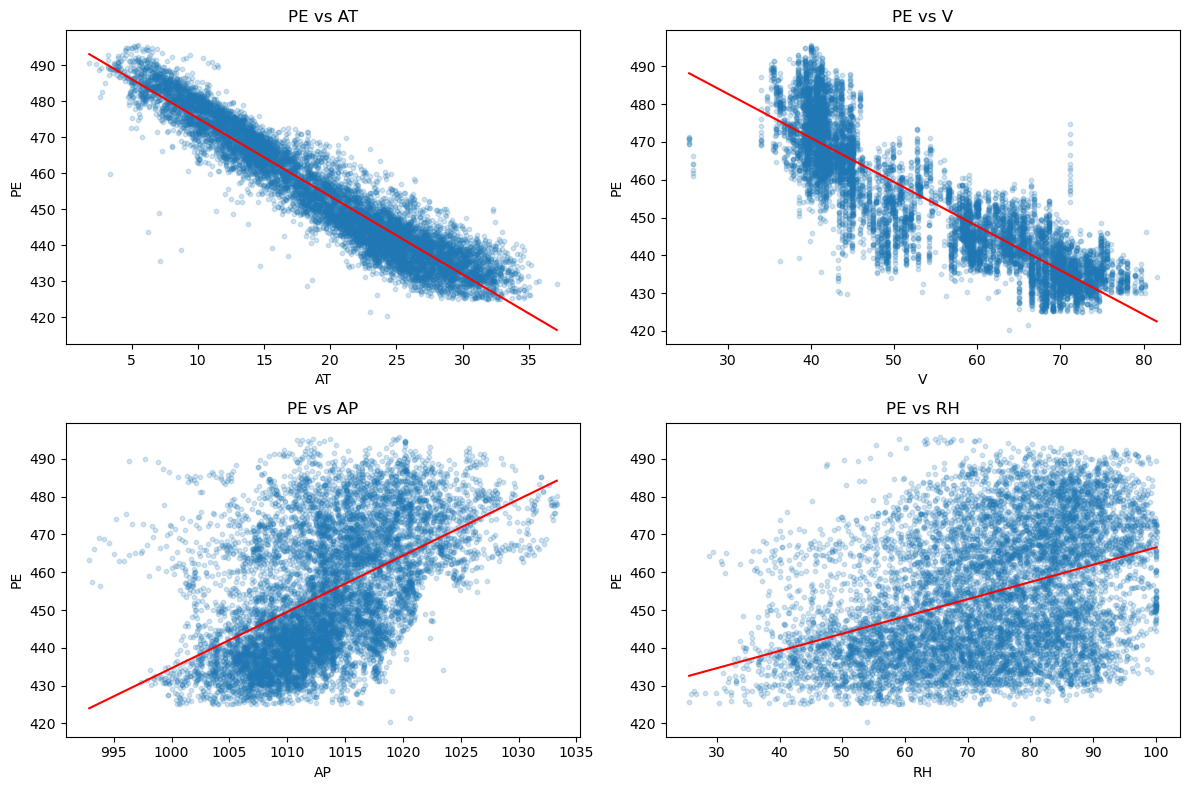

In [166]:

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, predictor in zip(axes.flat, predictors):
    model = simple_models[predictor]

    ax.scatter(df[predictor], df["PE"], alpha=0.2, s=10)

    x_sorted = df[[predictor]].sort_values(by=predictor)
    y_pred = model.predict(sm.add_constant(x_sorted))

    ax.plot(x_sorted[predictor], y_pred, color="red")
    ax.set_xlabel(predictor)
    ax.set_ylabel("PE")
    ax.set_title(f"PE vs {predictor}")

plt.tight_layout()
plt.show()


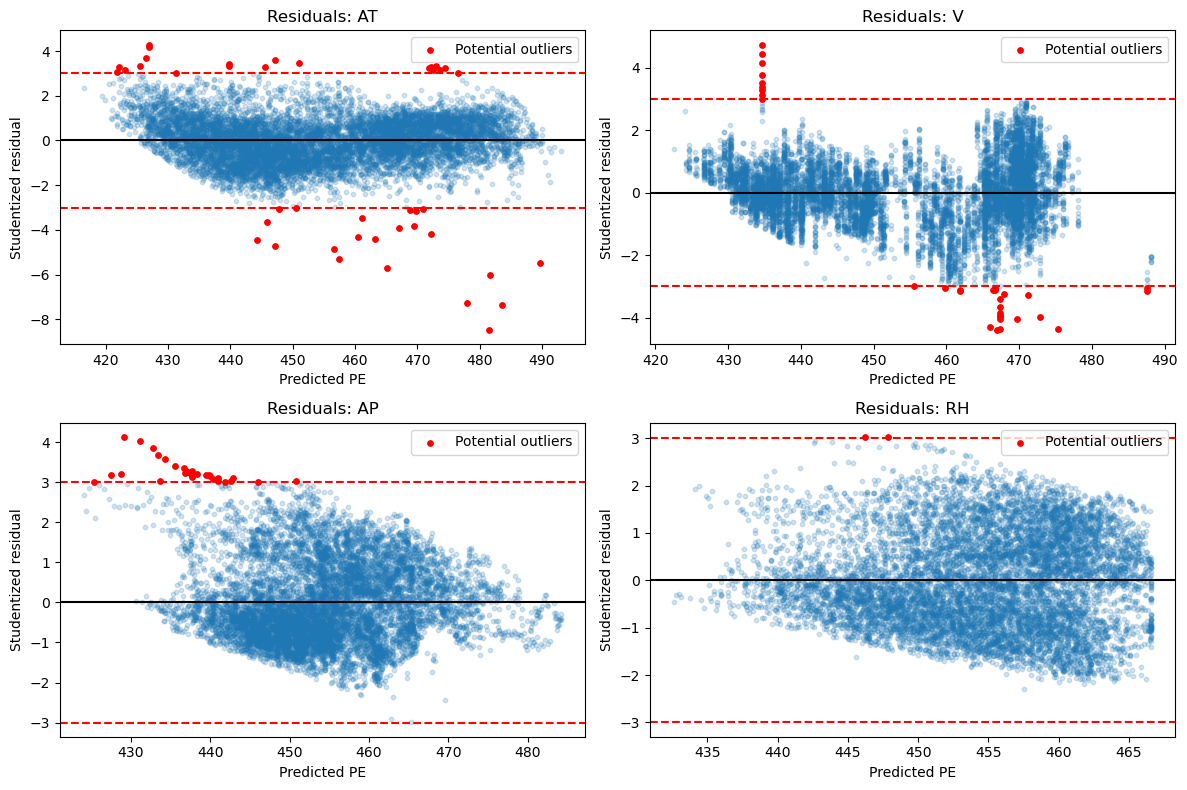

,Potential outliers
AT,42
V,33
AP,29
RH,2


In [167]:

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
outlier_counts = {}

for ax, predictor in zip(axes.flat, predictors):
    model = simple_models[predictor]

    residuals = model.get_influence().resid_studentized_internal
    outliers = abs(residuals) > 3
    outlier_counts[predictor] = outliers.sum()

    ax.scatter(
        model.fittedvalues, residuals,
        alpha=0.2, s=10
    )
    ax.scatter(
        model.fittedvalues[outliers], residuals[outliers],
        color="red", s=15, label="Potential outliers"
    )

    ax.axhline(0, color="black")
    ax.axhline(3, color="red", linestyle="--")
    ax.axhline(-3, color="red", linestyle="--")

    ax.set_xlabel("Predicted PE")
    ax.set_ylabel("Studentized residual")
    ax.set_title(f"Residuals: {predictor}")
    ax.legend()

plt.tight_layout()
plt.show()

pd.DataFrame.from_dict(
    outlier_counts,
    orient="index",
    columns=["Potential outliers"]
)

All four predictors have p-values below 0.05, showing statistically significant relationships with PE. AT and V have negative relationships with PE, while AP and RH have positive relationships.

AT provides the best fit (R² = 0.8989), followed by V (0.7565), AP (0.2688), and RH (0.1519).

Using residuals greater than 3, the models identify 42, 33, 29, and 2 potential outliers, respectively.

(d)  multiple regression model

In [168]:
X = sm.add_constant(df[["AT", "V", "AP", "RH"]])
y = df["PE"]

multiple_model = sm.OLS(y, X).fit()

print(multiple_model.summary())

                            OLS Regression Results                            
Dep. Variable:                     PE   R-squared:                       0.929
Model:                            OLS   Adj. R-squared:                  0.929
Method:                 Least Squares   F-statistic:                 3.114e+04
Date:                Mon, 21 Sep 2026   Prob (F-statistic):               0.00
Time:                        10:13:27   Log-Likelihood:                -28088.
No. Observations:                9568   AIC:                         5.619e+04
Df Residuals:                    9563   BIC:                         5.622e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        454.6093      9.749     46.634      0.0

All four predictors have p-values below 0.05, so we reject the null hypothesis H₀: βⱼ = 0 for each predictor.

Holding the other predictors constant, AT, V, and RH have negative relationships with PE, while AP has a positive relationship.

The model has an R² of 0.9287, explaining about 92.9% of the variation in PE.

(e) Comparing Regression Coefficients

,Simple,Multiple
AT,-2.1713,-1.9775
V,-1.1681,-0.2339
AP,1.4899,0.0621
RH,0.4557,-0.1581


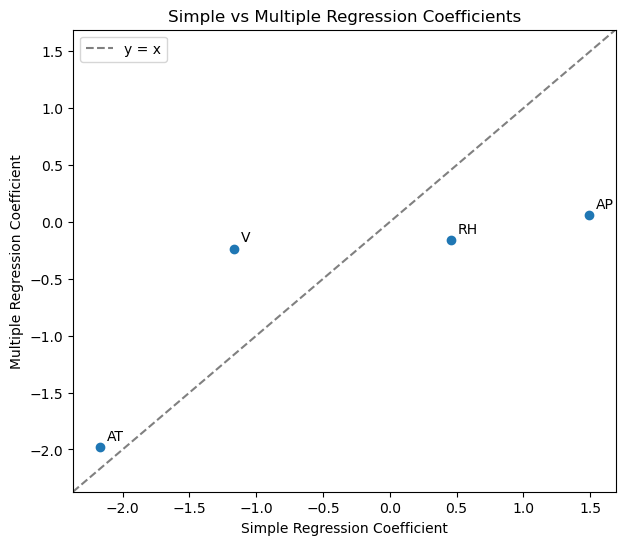

In [169]:
coefficients = pd.DataFrame({
    "Simple": [
        simple_models[p].params[p] for p in predictors
    ],
    "Multiple": [
        multiple_model.params[p] for p in predictors
    ]
}, index=predictors)

display(coefficients.round(4))

plt.figure(figsize=(7, 6))
plt.scatter(coefficients["Simple"], coefficients["Multiple"])

for p in predictors:
    plt.annotate(
        p,
        (coefficients.loc[p, "Simple"], coefficients.loc[p, "Multiple"]),
        xytext=(5, 5),
        textcoords="offset points"
    )

# Reference line: equal coefficients
limits = [
    coefficients.min().min() - 0.2,
    coefficients.max().max() + 0.2
]
plt.plot(limits, limits, "--", color="gray", label="y = x")
plt.xlim(limits)
plt.ylim(limits)

plt.xlabel("Simple Regression Coefficient")
plt.ylabel("Multiple Regression Coefficient")
plt.title("Simple vs Multiple Regression Coefficients")
plt.legend()
plt.show()

AT's coefficient changes relatively little, while the magnitudes of the V and AP coefficients decrease substantially. RH changes from positive to negative.

(f) nonlinear association

In [170]:
polynomial_models = {}
polynomial_inputs = {}
results_f = []

for predictor in predictors:
    x = (df[predictor] - df[predictor].mean()) / df[predictor].std()

    X = pd.DataFrame({
        "X": x,
        "X2": x ** 2,
        "X3": x ** 3
    })
    X = sm.add_constant(X)

    model = sm.OLS(df["PE"], X).fit()
    polynomial_models[predictor] = model
    polynomial_inputs[predictor] = X

    # Test whether the nonlinear terms are jointly significant
    nonlinear_test = model.f_test("X2 = 0, X3 = 0")

    results_f.append({
        "Predictor": predictor,
        "Linear R-squared": simple_models[predictor].rsquared,
        "Cubic R-squared": model.rsquared,
        "Nonlinear P-value": float(nonlinear_test.pvalue)
    })

results_f = pd.DataFrame(results_f).set_index("Predictor")
results_f

,Linear R-squared,Cubic R-squared,Nonlinear P-value
Predictor,,,
AT,0.898948,0.911883,3.478379e-285
V,0.756518,0.775022,7.040304e-165
AP,0.268769,0.297543,4.209145e-84
RH,0.151939,0.153743,3.799622e-05


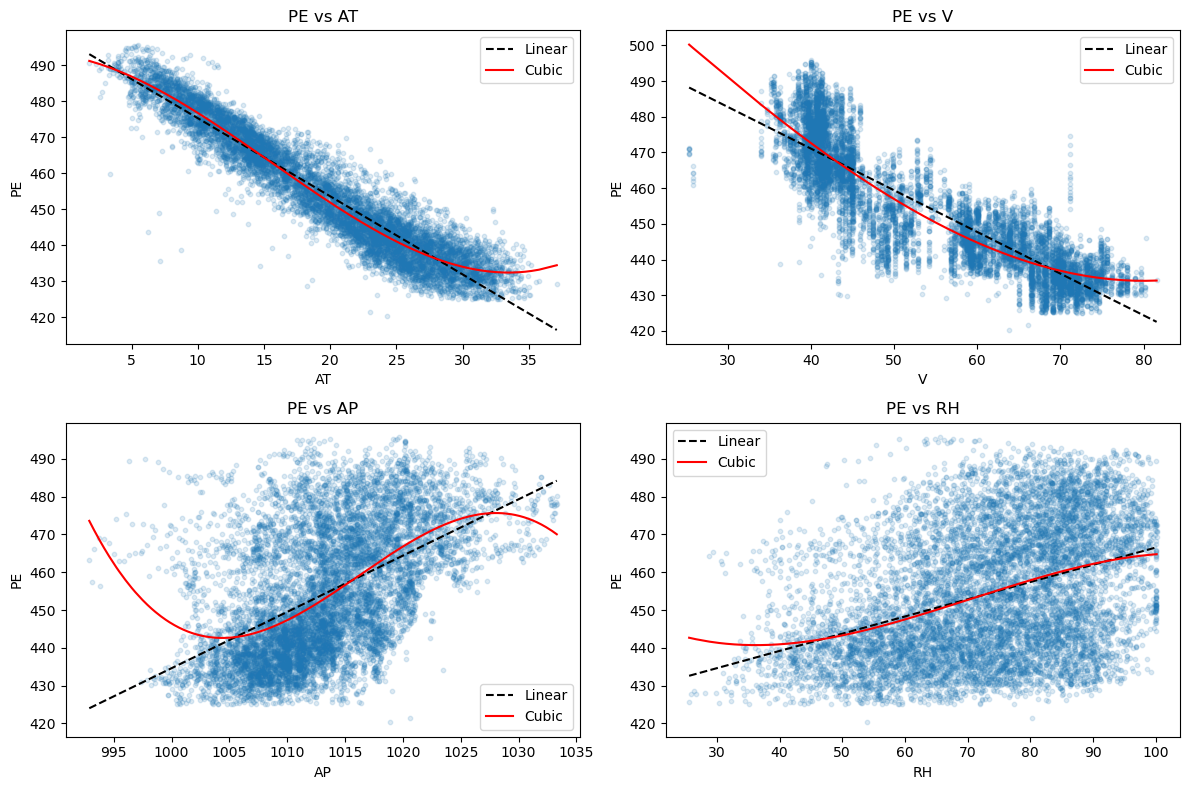

In [171]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, predictor in zip(axes.flat, predictors):
    order = df[predictor].sort_values().index
    x_sorted = df.loc[order, predictor]

    linear_pred = simple_models[predictor].predict(
        sm.add_constant(df.loc[order, [predictor]])
    )
    cubic_pred = polynomial_models[predictor].predict(
        polynomial_inputs[predictor].loc[order]
    )

    ax.scatter(df[predictor], df["PE"], alpha=0.15, s=10)
    ax.plot(x_sorted, linear_pred, color="black",
            linestyle="--", label="Linear")
    ax.plot(x_sorted, cubic_pred, color="red", label="Cubic")

    ax.set_xlabel(predictor)
    ax.set_ylabel("PE")
    ax.set_title(f"PE vs {predictor}")
    ax.legend()

plt.tight_layout()
plt.show()

Joint F-tests were used to test whether the quadratic and cubic coefficients were both zero.

All four tests have p-values below 0.05, providing evidence of nonlinear relationships between each predictor and PE.

The cubic models have higher R² values than the simple linear models. However, the improvement for RH is very small, from 0.1519 to 0.1537. Statistical significance does not necessarily imply a large improvement in fit.

(g) interaction effects

In [172]:
import statsmodels.formula.api as smf

interaction_model = smf.ols(
    "PE ~ (AT + V + AP + RH) ** 2",
    data=df
).fit()

print(interaction_model.summary())

                            OLS Regression Results                            
Dep. Variable:                     PE   R-squared:                       0.936
Model:                            OLS   Adj. R-squared:                  0.936
Method:                 Least Squares   F-statistic:                 1.405e+04
Date:                Mon, 21 Sep 2026   Prob (F-statistic):               0.00
Time:                        10:13:27   Log-Likelihood:                -27548.
No. Observations:                9568   AIC:                         5.512e+04
Df Residuals:                    9557   BIC:                         5.520e+04
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    685.7825     78.640      8.721      0.0

In [173]:
interaction_results = pd.DataFrame({
    "Coefficient": interaction_model.params,
    "P-value": interaction_model.pvalues
})

interaction_results = interaction_results.loc[
    interaction_results.index.str.contains(":")
]

interaction_results

,Coefficient,P-value
AT:V,0.020971,3.333358e-117
AT:AP,0.001759,4.520509e-01
AT:RH,-0.005230,1.216944e-10
V:AP,0.006812,2.877026e-07
V:RH,0.000839,8.619366e-02
AP:RH,-0.001612,3.360557e-02


At the 0.05 significance level, AT × V, AT × RH, V × AP, and AP × RH are significant. AT × AP and V × RH are not significant.

(h) improve model

simple multiple regression model

In [174]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

train, test = train_test_split(
    df, test_size=0.3, random_state=42
)

train = train.copy()
test = test.copy()

# Center predictors using training means for numerical stability
train_means = train[predictors].mean()
train[predictors] = train[predictors] - train_means
test[predictors] = test[predictors] - train_means

linear_model_h = smf.ols(
    "PE ~ AT + V + AP + RH",
    data=train
).fit()

add interaction terms and quadratic nonlinearities, and remove insignificant variables

In [175]:
higher_terms = [
    "I(AT ** 2)", "I(V ** 2)", "I(AP ** 2)", "I(RH ** 2)",
    "AT:V", "AT:AP", "AT:RH",
    "V:AP", "V:RH", "AP:RH"
]

while True:
    formula = "PE ~ " + " + ".join(predictors + higher_terms)
    improved_model_h = smf.ols(formula, data=train).fit()

    if not higher_terms:
        break

    p_values = improved_model_h.pvalues[higher_terms]
    worst_term = p_values.idxmax()

    if p_values[worst_term] <= 0.05:
        break

    print(f"Removed: {worst_term}, p = {p_values[worst_term]:.4f}")
    higher_terms.remove(worst_term)

print(improved_model_h.summary())

Removed: V:RH, p = 0.8674
Removed: I(V ** 2), p = 0.6077
Removed: V:AP, p = 0.3578
                            OLS Regression Results                            
Dep. Variable:                     PE   R-squared:                       0.938
Model:                            OLS   Adj. R-squared:                  0.938
Method:                 Least Squares   F-statistic:                     9258.
Date:                Mon, 21 Sep 2026   Prob (F-statistic):               0.00
Time:                        10:13:27   Log-Likelihood:                -19161.
No. Observations:                6697   AIC:                         3.835e+04
Df Residuals:                    6685   BIC:                         3.843e+04
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------

compare  train and test MSEs

In [176]:
results_h = []

for name, model in [
    ("Linear", linear_model_h),
    ("Quadratic + interactions", improved_model_h)
]:
    results_h.append({
        "Model": name,
        "Train MSE": mean_squared_error(
            train["PE"], model.predict(train)
        ),
        "Test MSE": mean_squared_error(
            test["PE"], model.predict(test)
        )
    })

pd.DataFrame(results_h).round(4)

,Model,Train MSE,Test MSE
0,Linear,20.5808,21.2399
1,Quadratic + interactions,17.8908,18.6600


The removed terms were V × RH, V², and V × AP. 

The expanded model has lower training and test MSEs. Quadratic terms and interactions improve prediction on this split.

(i) KNN Regression

In [177]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import MinMaxScaler

X_train = df.loc[train.index, predictors]
X_test = df.loc[test.index, predictors]
y_train = df.loc[train.index, "PE"]
y_test = df.loc[test.index, "PE"]

# Fit the scaler using training data only
scaler = MinMaxScaler()
X_train_norm = scaler.fit_transform(X_train)
X_test_norm = scaler.transform(X_test)

knn_results = {}

for name, X_tr, X_te in [
    ("Raw", X_train, X_test),
    ("Normalized", X_train_norm, X_test_norm)
]:
    results = []

    for k in range(1, 101):
        model = KNeighborsRegressor(n_neighbors=k)
        model.fit(X_tr, y_train)

        results.append({
            "k": k,
            "Train MSE": mean_squared_error(
                y_train, model.predict(X_tr)
            ),
            "Test MSE": mean_squared_error(
                y_test, model.predict(X_te)
            )
        })

    knn_results[name] = pd.DataFrame(results)

best_knn = pd.DataFrame({
    name: table.loc[table["Test MSE"].idxmin()]
    for name, table in knn_results.items()
}).T

best_knn["k"] = best_knn["k"].astype(int)
best_knn.round(4)

,k,Train MSE,Test MSE
Raw,5,10.6008,15.7268
Normalized,4,8.4543,14.2913


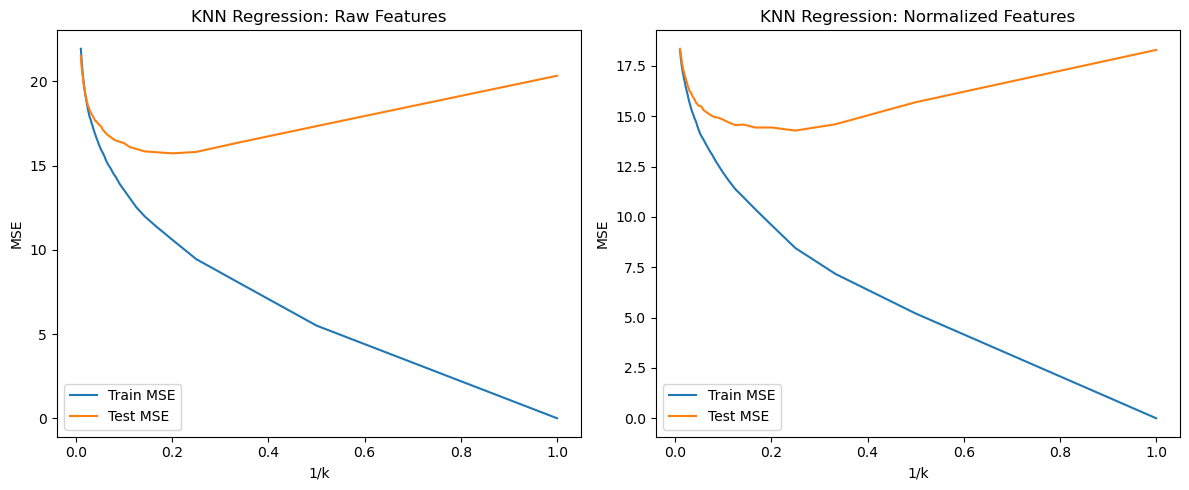

In [178]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (name, table) in zip(axes, knn_results.items()):
    table = table.sort_values("k", ascending=False)

    ax.plot(1 / table["k"], table["Train MSE"], label="Train MSE")
    ax.plot(1 / table["k"], table["Test MSE"], label="Test MSE")

    ax.set_xlabel("1/k")
    ax.set_ylabel("MSE")
    ax.set_title(f"KNN Regression: {name} Features")
    ax.legend()

plt.tight_layout()
plt.show()

Based on the lowest test MSE, the best k is 5 for raw features and 4 for normalized features. Normalization improves the best test MSE by reducing differences in feature scales, which affect KNN distances.

(j) Model Comparison

In [179]:
comparison = pd.DataFrame({
    "Model": [
        "Quadratic + interactions",
        "KNN (Raw, k=5)",
        "KNN (Normalized, k=4)"
    ],
    "Test MSE": [
        mean_squared_error(test["PE"], improved_model_h.predict(test)),
        best_knn.loc["Raw", "Test MSE"],
        best_knn.loc["Normalized", "Test MSE"]
    ]
})

comparison.round(4)

,Model,Test MSE
0,Quadratic + interactions,18.6600
1,"KNN (Raw, k=5)",15.7268
2,"KNN (Normalized, k=4)",14.2913


Both KNN models have lower test MSEs than the best regression model from part (h).

KNN can capture local, nonlinear patterns, and normalization helps prevent feature scales from dominating distance calculations. However, because k was selected using test errors, this comparison may favor KNN. An independent test set would provide a more reliable final comparison.

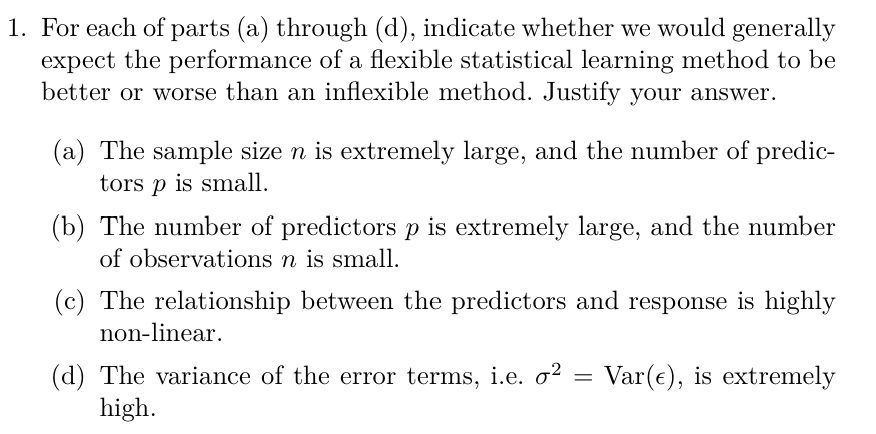

2.

(a) Better. When the sample size is very large and there are few predictors, a flexible method can learn complex patterns with less risk of overfitting.

(b) Worse. When there are many predictors but few observations, a flexible method is more likely to be overfitting.

(c) Better. When the relationship between the predictors and the response is highly nonlinear, a flexible method can capture this relationship more accurately.

(d) Worse. When the error variance is very high, a flexible method is more likely to fit the noise.

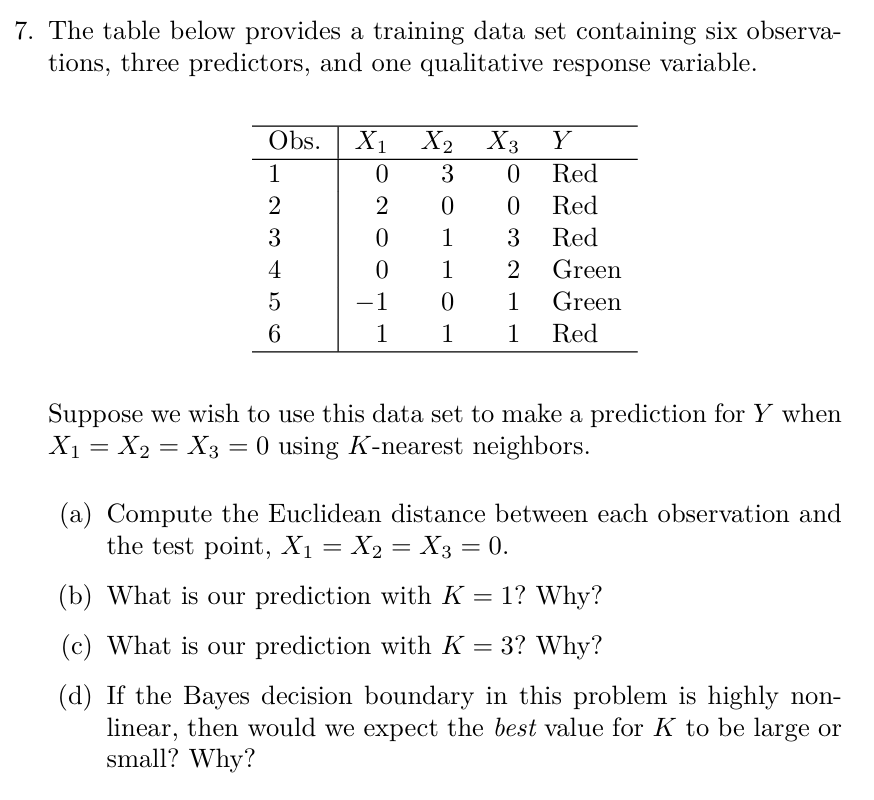

3.

(a) The Euclidean distances from observations 1 to 6 to the test point (0, 0, 0) are 3, 2, sqrt(10) ≈ 3.162, sqrt(5) ≈ 2.236, sqrt(2) ≈ 1.414, and sqrt(3) ≈ 1.732, respectively.

(b) When K = 1, the prediction is Green because the closest observation is observation 5, which is Green.

(c) When K = 3, the closest observations are 5, 6, and 2. Two are Red and one is Green, so the prediction is Red.

(d) We would expect a small K to perform better because it can capture a highly nonlinear decision boundary. A large K makes the boundary smoother and may miss complex patterns.